# Transfer learning: from arrhythmia to myocardial infarction

Following Kachuee et al. (2018), section III-C: the convolution layers trained on MIT-BIH arrhythmia beats in `ecg_classify_beats.ipynb` are frozen and used as a fixed representation of each beat, and only a small fully connected head is trained to classify PTB Diagnostic beats as **normal** or **myocardial infarction (MI)**. The same CNN trained from scratch on PTB is the baseline.

Run `ecg_classify_beats.ipynb` first: this notebook starts from its best checkpoint for the same architecture (`ECG_ARCH`, default `paper`; see `ecg_models.py`). Data is read from `./data` (or `ECG_DATA_DIR`); set `MI_EPOCHS=1` for a quick smoke test.

## 1. Import Required Libraries

In [1]:
import os
import random
from pathlib import Path
from typing import cast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)

import pytorch_lightning as pl
import torchmetrics
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint

from ecg_data import ECGDataset, load_ptbdb, PTB_CLASSES
from ecg_models import EcgLightningModule, make_ecg_model

DATA_DIR = os.environ.get("ECG_DATA_DIR", "./data")
# Which arrhythmia model to transfer from: "paper" (residual CNN) or "simple"; must match a
# checkpoint trained by ecg_classify_beats.ipynb with the same ECG_ARCH.
ARCH = os.environ.get("ECG_ARCH", "paper")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## 2. Model architectures

`EcgClassifier` (`simple`), `ResidualEcgClassifier` (`paper`) and `EcgLightningModule` are defined in `ecg_models.py`, shared with `ecg_classify_beats.ipynb`, so checkpoints always load into the same classes they were trained with. Both models provide `features(x)`, the beat representation used for transfer learning, and `feature_layers()`, the layers that compute it.

## 3. Load Best Checkpoint from Lightning Logs

Find the most recently modified arrhythmia checkpoint for `ARCH` (`ecg-<arch>-best-*.ckpt`) under `lightning_logs/` and load it. Checkpoints saved before the architecture switch (`ecg-best-*.ckpt`) are `simple` models.

In [2]:
notebook_dir = Path(".")

# Find all checkpoints under lightning_logs and pick the most recently modified one
patterns = [f"ecg-{ARCH}-best-*.ckpt"] + (["ecg-best-*.ckpt"] if ARCH == "simple" else [])
ckpt_files = sorted(
    (f for pattern in patterns for f in notebook_dir.glob(f"lightning_logs/**/checkpoints/{pattern}")),
    key=lambda p: p.stat().st_mtime,
)

if not ckpt_files:
    raise FileNotFoundError(f"No {ARCH!r} checkpoints under lightning_logs/. Run ecg_classify_beats.ipynb with ECG_ARCH={ARCH} first.")

ckpt_path = ckpt_files[-1]
print(f"Loading checkpoint: {ckpt_path}")

# Load the full Lightning module from the checkpoint.
# strict=False is required because class_weights is a registered buffer saved in the
# checkpoint state_dict, but is None (and thus absent) in the freshly constructed module.
# It is only needed for training loss — not for inference.
lightning_module = EcgLightningModule.load_from_checkpoint(
    ckpt_path,
    strict=False,
    map_location="cpu",  # checkpoints trained on CUDA load on any machine
)

# Extract just the inner nn.Module and set to eval mode
assert lightning_module.arch == ARCH, f"checkpoint is {lightning_module.arch!r}, expected {ARCH!r}"
model = lightning_module.model
model.eval()

print("Model loaded and set to eval() mode.")

Loading checkpoint: lightning_logs/version_3/checkpoints/ecg-simple-best-epoch=16-val_loss=0.3114.ckpt
Model loaded and set to eval() mode.


/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/core/saving.py:216: Found keys that are not in the model state dict but in the checkpoint: ['class_weights']


## 4. Inspect Model Structure

In [3]:
# Print the PyTorch module tree
print(model)

EcgClassifier(
  (conv1): Conv1d(1, 32, kernel_size=(5,), stride=(1,))
  (conv2): Conv1d(32, 64, kernel_size=(5,), stride=(1,))
  (pool): MaxPool1d(kernel_size=3, stride=3, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv1d(64, 128, kernel_size=(3,), stride=(1,))
  (conv4): Conv1d(128, 256, kernel_size=(3,), stride=(1,))
  (global_avg_pool): AdaptiveAvgPool1d(output_size=1)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=256, out_features=1024, bias=True)
  (fc2): Linear(in_features=1024, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=32, bias=True)
  (fc4): Linear(in_features=32, out_features=5, bias=True)
  (relu): ReLU()
)


In [4]:
import traceback

try:
    from torchinfo import summary
    model.cpu()
    # Pass an explicit dummy input so torchinfo doesn't have to guess the shape.
    # The model expects (batch, 187) flat signals; unsqueeze(1) happens internally.
    dummy = torch.zeros(1, 187)
    result = summary(
        model,
        input_data=dummy,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        verbose=0,
    )
    print(result)
except ImportError:
    print("torchinfo not installed — run `pip install torchinfo` for a detailed layer summary.")
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total parameters    : {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")
except Exception:
    traceback.print_exc()
    total_params = sum(p.numel() for p in model.parameters())
    print(f"\nTotal parameters    : {total_params:,}")

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Trainable
EcgClassifier                            [1, 187]                  [1, 5]                    --                        True
├─Conv1d: 1-1                            [1, 1, 187]               [1, 32, 183]              192                       True
├─ReLU: 1-2                              [1, 32, 183]              [1, 32, 183]              --                        --
├─Conv1d: 1-3                            [1, 32, 183]              [1, 64, 179]              10,304                    True
├─ReLU: 1-4                              [1, 64, 179]              [1, 64, 179]              --                        --
├─MaxPool1d: 1-5                         [1, 64, 179]              [1, 64, 59]               --                        --
├─Conv1d: 1-6                            [1, 64, 59]               [1, 128, 57]              24,704                    True
├─ReLU: 1

## 5. PTB Diagnostic data

Lead II beats from the PTB Diagnostic ECG Database, in the same 187-sample format as MIT-BIH: `ptbdb_normal.csv` (label 0) and `ptbdb_abnormal.csv` (label 1, MI).

In [5]:
ptb = load_ptbdb(DATA_DIR)
labels = ptb.iloc[:, -1].to_numpy().astype(int)
classes, counts = np.unique(labels, return_counts=True)
print(f"{len(ptb):,} beats:", {PTB_CLASSES[c]: int(n) for c, n in zip(classes, counts)})

14,552 beats: {'Normal': 4046, 'MI': 10506}


The paper trains on 80% of PTB and tests on the remaining 20%. The same 20% is held out for testing here, and an eighth of the training portion (10% of all beats) is set aside for validation, which drives early stopping and checkpoint selection. All splits are stratified so both classes keep their proportions.

**Caveat:** the Kaggle CSVs hold individual beats with no patient IDs, so this split is random by beat, not by patient. Beats from the same patient will appear in both the training and test sets, so the models can partly recognise the patient rather than the condition. Every score in this notebook (and the paper's) is therefore optimistic for unseen patients, and the high-capacity from-scratch model probably benefits most.

In [6]:
idx = np.arange(len(ptb))
trainval_idx, test_idx = train_test_split(idx, test_size=0.2, stratify=labels, random_state=SEED)
train_idx, val_idx = train_test_split(trainval_idx, test_size=0.125, stratify=labels[trainval_idx], random_state=SEED)
print(f"train {len(train_idx):,} | val {len(val_idx):,} | test {len(test_idx):,}")

# PTB is small: a full pass over the training split takes about a second in the main
# process, so worker processes would only add start-up stalls (several seconds each on macOS).
def make_loader(rows, shuffle):
    return DataLoader(ECGDataset(ptb.iloc[rows]), batch_size=64, shuffle=shuffle, num_workers=0)

train_dl = make_loader(train_idx, shuffle=True)
val_dl = make_loader(val_idx, shuffle=False)
test_dl = make_loader(test_idx, shuffle=False)

# Inverse-frequency class weights from the training split (MI beats outnumber normal about 2.6 : 1)
train_counts = np.bincount(labels[train_idx], minlength=2)
class_weights = torch.tensor(train_counts.sum() / (2 * train_counts), dtype=torch.float32)
print("class weights:", {PTB_CLASSES[c]: round(float(w), 3) for c, w in enumerate(class_weights)})

train 10,185 | val 1,456 | test 2,911
class weights: {'Normal': 1.798, 'MI': 0.693}


## 6. Models

The beat representation is `backbone.features(x)`, the output of the last convolution layer: 64 values per beat for the `paper` model (32 channels × 2 positions), 256 for `simple` (after global average pooling). Three models are compared:

- **Frozen features** (the paper's setup): the convolution layers trained on MIT-BIH are frozen, and only a new head is trained: two fully connected layers (features → 32 → 2), matching the paper's "we only train the last two network layers".
- **Fine-tuned**: the same start, but the convolution layers keep training too, at a tenth of the head's learning rate, so they can adapt to MI features without losing what they learned.
- **From scratch** (baseline): the same CNN with a two-class output, randomly initialised and trained end to end on PTB.

In [7]:
class MiTransferModel(nn.Module):
    """An arrhythmia model's feature layers + a new MI head of two fully connected layers.

    freeze=True: the feature layers are a fixed feature extractor; only the head trains.
    freeze=False: fine-tuning; the feature layers train too (at the lower `backbone_lr`
    given to BeatClassifier). The arrhythmia model's own classifier layers are unused.
    """

    def __init__(self, backbone: nn.Module, freeze: bool = True):
        super().__init__()
        self.freeze = freeze
        self.backbone = backbone.requires_grad_(False)
        if not freeze:
            for layer in backbone.feature_layers():
                layer.requires_grad_(True)
        self.head = nn.Sequential(
            nn.Linear(backbone.feature_dim, 32), nn.ReLU(),
            nn.Linear(32, 2),
        )

    def forward(self, x):
        if self.freeze:
            with torch.no_grad():
                features = self.backbone.features(x)
        else:
            features = self.backbone.features(x)
        return self.head(features)


def scratch_model() -> nn.Module:
    """Baseline: the same architecture, randomly initialised, with a two-class output; every layer is trained."""
    return make_ecg_model(ARCH, num_classes=2)


class BeatClassifier(pl.LightningModule):
    """Trains a beat model with class-weighted cross-entropy. Only parameters that require
    gradients are optimised, so a frozen backbone stays frozen. If `backbone_lr` is given,
    the model's backbone parameters train at that rate and everything else at `learning_rate`."""

    def __init__(self, model: nn.Module, class_weights: torch.Tensor,
                 learning_rate: float = 1e-3, weight_decay: float = 1e-4,
                 backbone_lr: float | None = None):
        super().__init__()
        self.model = model
        self.learning_rate = learning_rate
        self.backbone_lr = backbone_lr
        self.weight_decay = weight_decay
        self.register_buffer("class_weights", class_weights)
        self.val_acc = torchmetrics.classification.BinaryAccuracy()

    def forward(self, x):
        return self.model(x)

    def _loss(self, batch):
        x, y = batch
        logits = self(x)
        return F.cross_entropy(logits, y, weight=self.class_weights), logits, y

    def training_step(self, batch, batch_idx):
        loss, _, _ = self._loss(batch)
        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        loss, logits, y = self._loss(batch)
        self.val_acc(logits.argmax(dim=1), y)
        self.log("val_loss", loss, on_epoch=True, prog_bar=True)
        self.log("val_acc", self.val_acc, on_epoch=True, prog_bar=True)

    def predict_step(self, batch, batch_idx):
        x, _ = batch
        return self(x).softmax(dim=1)[:, 1]  # probability of MI

    def configure_optimizers(self):
        trainable = [(n, p) for n, p in self.named_parameters() if p.requires_grad]
        if self.backbone_lr is None:
            groups = [{"params": [p for _, p in trainable]}]
        else:
            in_backbone = lambda n: n.startswith("model.backbone.")
            groups = [{"params": [p for n, p in trainable if in_backbone(n)], "lr": self.backbone_lr},
                      {"params": [p for n, p in trainable if not in_backbone(n)]}]
        optimizer = torch.optim.AdamW(groups, lr=self.learning_rate, weight_decay=self.weight_decay)
        scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3, min_lr=1e-6)
        return {"optimizer": optimizer,
                "lr_scheduler": {"scheduler": scheduler, "monitor": "val_loss", "interval": "epoch"}}

In [8]:
def epoch_limit(default: int) -> int:
    """Each model has its own epoch limit (early stopping usually ends training first).
    Setting MI_EPOCHS overrides them all, e.g. MI_EPOCHS=1 for a quick smoke test."""
    return int(os.environ.get("MI_EPOCHS", default))


def fit(module: BeatClassifier, name: str, max_epochs: int) -> pl.Trainer:
    """Train with early stopping on validation loss, keeping the best checkpoint."""
    checkpoint = ModelCheckpoint(monitor="val_loss", mode="min", save_top_k=1,
                                 filename=f"{name}-best-{{epoch:02d}}-{{val_loss:.4f}}")
    trainer = pl.Trainer(
        max_epochs=max_epochs,
        accelerator="auto",  # CUDA on Linux, MPS on Apple Silicon
        # Kept apart from lightning_logs/, where section 3 looks for the arrhythmia checkpoint.
        default_root_dir="lightning_logs_mi",
        callbacks=[EarlyStopping(monitor="val_loss", mode="min", patience=10), checkpoint],
        log_every_n_steps=10,
        enable_model_summary=False,
    )
    trainer.fit(module, train_dl, val_dl)
    print(f"{name}: best val_loss {checkpoint.best_model_score:.4f} ({checkpoint.best_model_path})")
    return trainer


def evaluate(trainer: pl.Trainer, module: BeatClassifier, name: str) -> dict:
    """Score the best checkpoint on the held-out test split. MI is the positive class."""
    batches = trainer.predict(module, test_dl, ckpt_path="best")
    probs = torch.cat(cast(list[torch.Tensor], batches)).float().cpu().numpy()
    truth = labels[test_idx]
    preds = (probs >= 0.5).astype(int)
    print(f"=== {name}: test set, {len(truth):,} beats ===")
    print(classification_report(truth, preds, target_names=list(PTB_CLASSES.values()), digits=4))
    ConfusionMatrixDisplay.from_predictions(truth, preds, display_labels=list(PTB_CLASSES.values()),
                                            normalize="true", values_format=".3f", cmap="Blues")
    plt.title(f"{name}: test set (row-normalised)")
    plt.show()
    return {
        "Accuracy": accuracy_score(truth, preds),
        "Precision (MI)": precision_score(truth, preds),
        "Recall (MI)": recall_score(truth, preds),
        "Precision (macro)": precision_score(truth, preds, average="macro"),
        "Recall (macro)": recall_score(truth, preds, average="macro"),
        "F1 (MI)": f1_score(truth, preds),
        "ROC AUC": roc_auc_score(truth, probs),
    }

## 7. Transfer learning: frozen arrhythmia features, new head

Only the small head learns here, from fixed features, so it can converge slowly (with the `simple` model it was still improving after 100 epochs). It gets up to 300 epochs and a higher learning rate (3e-3); early stopping ends the run once validation loss stops improving.

In [9]:
pl.seed_everything(SEED, workers=True)

backbone = EcgLightningModule.load_from_checkpoint(ckpt_path, strict=False, map_location="cpu").model
transfer = BeatClassifier(MiTransferModel(backbone, freeze=True), class_weights, learning_rate=3e-3)

trainable = sum(p.numel() for p in transfer.parameters() if p.requires_grad)
total = sum(p.numel() for p in transfer.parameters())
print(f"Trainable parameters: {trainable:,} of {total:,}")

transfer_trainer = fit(transfer, "mi-transfer", max_epochs=epoch_limit(300))

Seed set to 42
/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/core/saving.py:216: Found keys that are not in the model state dict but in the checkpoint: ['class_weights']
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which

Trainable parameters: 8,290 of 676,007


/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


mi-transfer: best val_loss 0.2547 (lightning_logs_mi/lightning_logs/version_5/checkpoints/mi-transfer-best-epoch=84-val_loss=0.2547.ckpt)


Epoch 94: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 160/160 [00:02<00:00, 69.12it/s, v_num=5, val_loss=0.255, val_acc=0.910, train_loss=0.220]


Restoring states from the checkpoint path at lightning_logs_mi/lightning_logs/version_5/checkpoints/mi-transfer-best-epoch=84-val_loss=0.2547.ckpt
Loaded model weights from the checkpoint at lightning_logs_mi/lightning_logs/version_5/checkpoints/mi-transfer-best-epoch=84-val_loss=0.2547.ckpt
/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


=== Frozen features: test set, 2,911 beats ===
              precision    recall  f1-score   support

      Normal     0.7701    0.8986    0.8294       809
          MI     0.9583    0.8968    0.9265      2102

    accuracy                         0.8973      2911
   macro avg     0.8642    0.8977    0.8780      2911
weighted avg     0.9060    0.8973    0.8995      2911


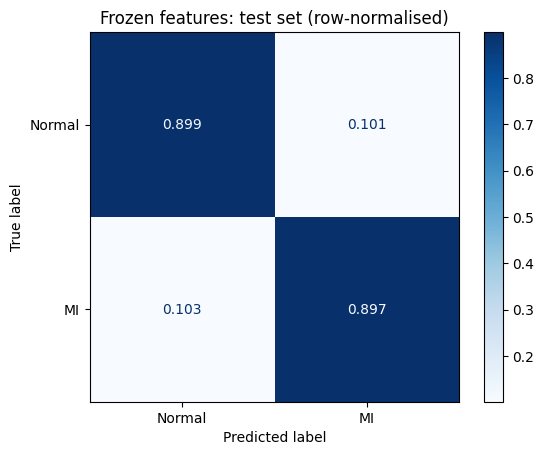

In [10]:
transfer_results = evaluate(transfer_trainer, transfer, "Frozen features")

## 8. Fine-tuning: arrhythmia weights as the starting point

Same arrhythmia backbone and new head, but the feature layers (all the convolutions) keep training, at a tenth of the head's learning rate (1e-4 against 1e-3), so they adapt to MI features without discarding what they learned on MIT-BIH.

In [11]:
pl.seed_everything(SEED, workers=True)

backbone = EcgLightningModule.load_from_checkpoint(ckpt_path, strict=False, map_location="cpu").model
finetune = BeatClassifier(MiTransferModel(backbone, freeze=False), class_weights,
                          learning_rate=1e-3, backbone_lr=1e-4)

trainable = sum(p.numel() for p in finetune.parameters() if p.requires_grad)
print(f"Trainable parameters: {trainable:,} (feature layers + head)")

finetune_trainer = fit(finetune, "mi-finetune", max_epochs=epoch_limit(100))

Seed set to 42


Trainable parameters: 142,050 (feature layers + head)


/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/core/saving.py:216: Found keys that are not in the model state dict but in the checkpoint: ['class_weights']
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


mi-finetune: best val_loss 0.0624 (lightning_logs_mi/lightning_logs/version_6/checkpoints/mi-finetune-best-epoch=38-val_loss=0.0624.ckpt)


Epoch 48: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 160/160 [00:02<00:00, 55.20it/s, v_num=6, val_loss=0.0663, val_acc=0.985, train_loss=0.022]


Restoring states from the checkpoint path at lightning_logs_mi/lightning_logs/version_6/checkpoints/mi-finetune-best-epoch=38-val_loss=0.0624.ckpt
Loaded model weights from the checkpoint at lightning_logs_mi/lightning_logs/version_6/checkpoints/mi-finetune-best-epoch=38-val_loss=0.0624.ckpt
/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


=== Fine-tuned: test set, 2,911 beats ===
              precision    recall  f1-score   support

      Normal     0.9464    0.9827    0.9642       809
          MI     0.9932    0.9786    0.9859      2102

    accuracy                         0.9797      2911
   macro avg     0.9698    0.9806    0.9750      2911
weighted avg     0.9802    0.9797    0.9798      2911


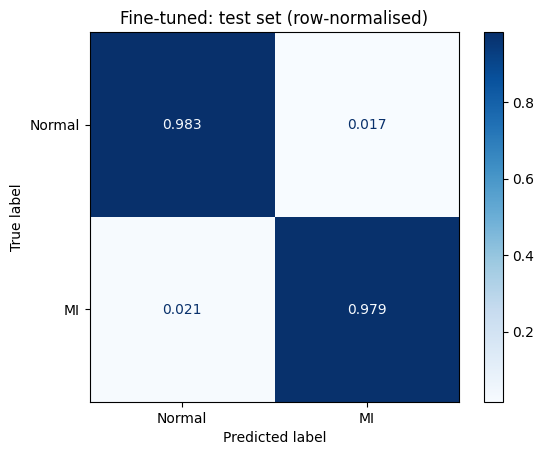

In [12]:
finetune_results = evaluate(finetune_trainer, finetune, "Fine-tuned")

## 9. Baseline: the same CNN trained from scratch on PTB heart attack data

In [13]:
pl.seed_everything(SEED, workers=True)

scratch = BeatClassifier(scratch_model(), class_weights)
print(f"Trainable parameters: {sum(p.numel() for p in scratch.parameters()):,}")

scratch_trainer = fit(scratch, "mi-scratch", max_epochs=epoch_limit(100))

Seed set to 42


Trainable parameters: 667,618


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


mi-scratch: best val_loss 0.0793 (lightning_logs_mi/lightning_logs/version_7/checkpoints/mi-scratch-best-epoch=35-val_loss=0.0793.ckpt)


Epoch 45: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 160/160 [00:03<00:00, 51.07it/s, v_num=7, val_loss=0.159, val_acc=0.980, train_loss=0.0147]


Restoring states from the checkpoint path at lightning_logs_mi/lightning_logs/version_7/checkpoints/mi-scratch-best-epoch=35-val_loss=0.0793.ckpt
Loaded model weights from the checkpoint at lightning_logs_mi/lightning_logs/version_7/checkpoints/mi-scratch-best-epoch=35-val_loss=0.0793.ckpt
/Users/michaelwebster/.pyenv/versions/ml312/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


=== From scratch: test set, 2,911 beats ===
              precision    recall  f1-score   support

      Normal     0.9622    0.9765    0.9693       809
          MI     0.9909    0.9853    0.9881      2102

    accuracy                         0.9828      2911
   macro avg     0.9766    0.9809    0.9787      2911
weighted avg     0.9829    0.9828    0.9829      2911


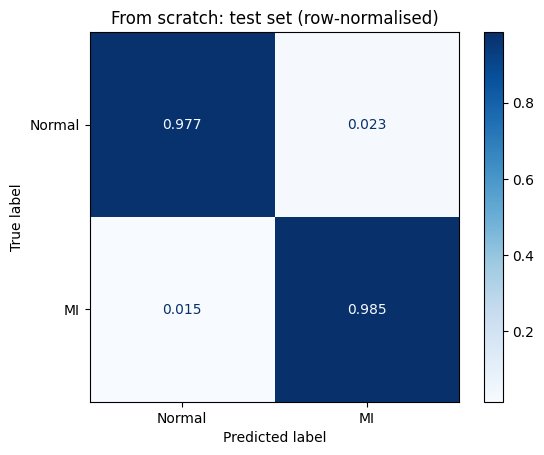

In [14]:
scratch_results = evaluate(scratch_trainer, scratch, "From scratch")

## 10. Comparison

Kachuee et al. report **95.9% accuracy, 95.2% precision and 95.1% recall** for MI classification on PTB lead II, with frozen features from their residual network (the `paper` architecture here). They describe these as average figures, so the macro-averaged columns are the closest comparison.

- **Frozen features vs from scratch** shows how far the arrhythmia representation gets on its own; it trains about 1/70th of the parameters.
- **Fine-tuned vs from scratch** shows whether starting from arrhythmia weights helps when the convolution layers can adapt.
- Remember the caveat in section 5: beats from the same patient appear in both training and test sets, so all of these scores are optimistic for unseen patients.

In [15]:
(pd.DataFrame({"Frozen features": transfer_results, "Fine-tuned": finetune_results, "From scratch": scratch_results}).T * 100).round(2)

,Accuracy,Precision (MI),Recall (MI),Precision (macro),Recall (macro),F1 (MI),ROC AUC
Frozen features,89.73,95.83,89.68,86.42,89.77,92.65,96.07
Fine-tuned,97.97,99.32,97.86,96.98,98.06,98.59,99.74
From scratch,98.28,99.09,98.53,97.66,98.09,98.81,99.68
